# Etapa 2 — Análise Exploratória de Dados

Entrada: os CSVs que a Etapa 1 gravou em `../data/raw/`.
Saída: uma tabela horária limpa em `../data/processed/dataset.csv`, mais os
gráficos e as conclusões que sustentam o que você vai afirmar.

As seções abaixo são um roteiro, não uma receita. Responda as perguntas de
cada uma com código e, no fim, em texto. Acrescente seções se quiser.

In [839]:
from pathlib import Path

DIR_RAW = Path("..") / "data" / "raw"
DIR_PROC = Path("..") / "data" / "processed"
DIR_PROC.mkdir(parents=True, exist_ok=True)

# TODO: imports (pandas, matplotlib, seaborn, ...)

In [840]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path

## 1. Carregar os CSVs

Leia os quatro arquivos de `../data/raw/`.

- Quantas linhas tem cada um? O número faz sentido para o período coletado?
- Os tipos vieram certos, ou datas e números chegaram como texto?
- Há colunas vazias, ou linhas duplicadas?

In [841]:
pd.set_option("display.max_columns", None)
sns.set_theme(style="whitegrid")

path_mares_2025 = DIR_RAW / "mares_2025.csv"
path_mares_prev = DIR_RAW / "mares_previsao.csv"
path_ondas = DIR_RAW / "ondas.csv"
path_vento = DIR_RAW / "vento.csv"

df_mares_2025 = pd.read_csv(path_mares_2025)
df_mares_prev = pd.read_csv(path_mares_prev)
df_ondas = pd.read_csv(path_ondas)
df_vento = pd.read_csv(path_vento)

In [842]:
print("=== MARÉS 2025 ===")

print(f"Dimensões: {df_mares_2025.shape[0]} linhas e {df_mares_2025.shape[1]} colunas")

display(df_mares_2025.sample())

df_mares_2025.info()

print("\nValores ausentes:")
print(df_mares_2025.isna().sum())

print(f"\nLinhas duplicadas: {df_mares_2025.duplicated().sum()}")

print("\nEstatísticas das colunas:")
display(df_mares_2025.describe())


=== MARÉS 2025 ===
Dimensões: 1410 linhas e 3 colunas


,data_hora,altura_m,coeficiente
283,2025-03-15 10:39,"2,4",88alto


<class 'pandas.DataFrame'>
RangeIndex: 1410 entries, 0 to 1409
Data columns (total 3 columns):
 #   Column       Non-Null Count  Dtype
---  ------       --------------  -----
 0   data_hora    1410 non-null   str  
 1   altura_m     1410 non-null   str  
 2   coeficiente  1410 non-null   str  
dtypes: str(3)
memory usage: 33.2 KB

Valores ausentes:
data_hora      0
altura_m       0
coeficiente    0
dtype: int64

Linhas duplicadas: 0

Estatísticas das colunas:


,data_hora,altura_m,coeficiente
count,1410,1410,1410
unique,1410,44,81
top,2025-01-01 5:50,"0,8m",59médio
freq,1,61,42


Resumo das colunos:

Todas as linhas estam completas e sem duplicats. As colunas altura_m e coeficiente varia poucos, têm 34 e 25 dados únicos respectivamente.
* data_hora: está como string, isso é coerente com o formato do dados.
* altura_m: está como string e com formato inconsistente, será preciso fazer um limpeza
* coeficiente: está string no formato de valor númerico + classificação escrita (baixa-muito alto). Penso em dividir em duas colunas ou em apenas uma coluna númerica e gaurdar as informações que definem este coeficiente como baixo ou alto e usar como filtro (ex: acima de 90 é muito alto)

In [843]:
print("=== PREVISÃO DE MARÉS ===")

print(f"Dimensões: {df_mares_prev.shape[0]} linhas e {df_mares_prev.shape[1]} colunas")

display(df_mares_prev.head())

df_mares_prev.info()

print("\nValores ausentes:")
print(df_mares_prev.isna().sum())

print(f"\nLinhas duplicadas: {df_mares_prev.duplicated().sum()}")

print("\nEstatísticas das colunas:")
display(df_mares_prev.describe(include="all"))


=== PREVISÃO DE MARÉS ===
Dimensões: 120 linhas e 3 colunas


,data_hora,altura_m,coeficiente
0,2026-10-01 4:29,"2,3m",98muito alto
1,2026-10-01 10:31,"2,3",98muito alto
2,2026-10-01 16:44,"0,3m",98muito alto
3,2026-10-01 23:07,"0,3",98muito alto
4,2026-10-02 5:15,"2,5m",99muito alto


<class 'pandas.DataFrame'>
RangeIndex: 120 entries, 0 to 119
Data columns (total 3 columns):
 #   Column       Non-Null Count  Dtype
---  ------       --------------  -----
 0   data_hora    120 non-null    str  
 1   altura_m     120 non-null    str  
 2   coeficiente  120 non-null    str  
dtypes: str(3)
memory usage: 2.9 KB

Valores ausentes:
data_hora      0
altura_m       0
coeficiente    0
dtype: int64

Linhas duplicadas: 0

Estatísticas das colunas:


,data_hora,altura_m,coeficiente
count,120,120,120
unique,120,34,25
top,2026-10-01 4:29,"0,5m",78alto
freq,1,8,12


In [844]:

print("=== MARÉS 2025 ===")
print("Primeiro registro:", df_mares_2025["data_hora"].min())
print("Último registro:", df_mares_2025["data_hora"].max())

print("\n=== PREVISÃO DE MARÉS ===")
print("Primeiro registro:", df_mares_prev["data_hora"].min())
print("Último registro:", df_mares_prev["data_hora"].max())


=== MARÉS 2025 ===
Primeiro registro: 2025-01-01 12:00
Último registro: 2025-12-31 8:22

=== PREVISÃO DE MARÉS ===
Primeiro registro: 2026-10-01 10:31
Último registro: 2026-10-31 4:57


O df_mares_prev tem os emsmo problemas do df_mares_2025. O que muda é apenos o período, que agora é o o mês de outubro de 2026 e no anterior foi o ano de 2025 completo.

Observação: os dos datasets tem os mesmos valores únicos para as colunas altura_m e coeficiente, isso demostra um possível padrão para a análise e execução dos próximos passos.

In [845]:
print("=== ONDAS ===")

print(f"Dimensões: {df_ondas.shape[0]} linhas e {df_ondas.shape[1]} colunas")

display(df_ondas.sample(5))

df_ondas.info()

print("\nValores ausentes:")
print(df_ondas.isna().sum())

print("\nLinhas duplicadas:")
print(df_ondas.duplicated().sum())

print("\nEstatísticas das colunas:")
display(df_ondas.describe(include="all"))

=== ONDAS ===
Dimensões: 168 linhas e 3 colunas


,data_hora,direcao_onda,altura_onda
121,2026-10-16 1:00,E,"1,3m"
92,2026-10-14 20:00,E,"1,3m"
124,2026-10-16 4:00,E,"1,3m"
138,2026-10-16 18:00,E,"1,2m"
20,2026-10-11 20:00,E,"1,0m"


<class 'pandas.DataFrame'>
RangeIndex: 168 entries, 0 to 167
Data columns (total 3 columns):
 #   Column        Non-Null Count  Dtype
---  ------        --------------  -----
 0   data_hora     168 non-null    str  
 1   direcao_onda  168 non-null    str  
 2   altura_onda   168 non-null    str  
dtypes: str(3)
memory usage: 4.1 KB

Valores ausentes:
data_hora       0
direcao_onda    0
altura_onda     0
dtype: int64

Linhas duplicadas:
0

Estatísticas das colunas:


,data_hora,direcao_onda,altura_onda
count,168,168,168
unique,168,2,6
top,2026-10-11 0:00,E,"1,2m"
freq,1,150,69


Resumo das colunas:
Sem linhas com valores nulos ou duplicatas.
* data_hora: está como  string e segue o formato padrão dos datasets anteriores.
* direcao_onda: só tem duas direções (E e ESE)
* altura_onda: está como string e vai precisar de um limpeza para virar uma coluna número sem o 'm', pretendo mudar o nome da coluna para altura_onda_m

In [846]:
print("=== VENTO ===")

print(f"Dimensões: {df_vento.shape[0]} linhas e {df_vento.shape[1]} colunas")

display(df_vento.sample(5))

df_vento.info()

print("\nValores ausentes:")
print(df_vento.isna().sum())

print(f"\nLinhas duplicadas: {df_vento.duplicated().sum()}")

print("\nEstatísticas das colunas:")
display(df_vento.describe(include="all"))

print("\nExemplos de valores únicos:")
for coluna in df_vento.columns:
    print(f"\n{coluna}:")
    print(df_vento[coluna].unique()[:10])


=== VENTO ===
Dimensões: 168 linhas e 3 colunas


,data_hora,direcao_vento,velocidade_vento
70,2026-10-13 22:00,ESE,20 km/h
45,2026-10-12 21:00,ESE,26 km/h
91,2026-10-14 19:00,E,19 km/h
106,2026-10-15 10:00,ENE,18 km/h
68,2026-10-13 20:00,ESE,21 km/h


<class 'pandas.DataFrame'>
RangeIndex: 168 entries, 0 to 167
Data columns (total 3 columns):
 #   Column            Non-Null Count  Dtype
---  ------            --------------  -----
 0   data_hora         168 non-null    str  
 1   direcao_vento     168 non-null    str  
 2   velocidade_vento  168 non-null    str  
dtypes: str(3)
memory usage: 4.1 KB

Valores ausentes:
data_hora           0
direcao_vento       0
velocidade_vento    0
dtype: int64

Linhas duplicadas: 0

Estatísticas das colunas:


,data_hora,direcao_vento,velocidade_vento
count,168,168,168
unique,168,4,16
top,2026-10-11 0:00,ESE,21 km/h
freq,1,65,35



Exemplos de valores únicos:

data_hora:
<StringArray>
['2026-10-11 0:00', '2026-10-11 1:00', '2026-10-11 2:00', '2026-10-11 3:00',
 '2026-10-11 4:00', '2026-10-11 5:00', '2026-10-11 6:00', '2026-10-11 7:00',
 '2026-10-11 8:00', '2026-10-11 9:00']
Length: 10, dtype: str

direcao_vento:
<StringArray>
['ESE', 'SE', 'E', 'ENE']
Length: 4, dtype: str

velocidade_vento:
<StringArray>
['22 km/h', '21 km/h', '19 km/h', '18 km/h', '24 km/h', '29 km/h', '30 km/h',
 '28 km/h', '25 km/h', '23 km/h']
Length: 10, dtype: str


Resumo das colunas:
As linhas não têm valores faltando ou duplicatas e todas as colunas são de strings
* data_hora: mesmo caso das anteriores
* direcao_vento: o vento tem 4 direções diferente (SE, ESE, E e ENE)
* velocidade_vento: precisa passar por uma limpeza e transformar a coluna em inteiro, apresenta 15 variações de velocidade.

## 2. Limpeza

Deixe cada tabela num estado em que dá para confiar.

- Datas e horas: viram `datetime`? Vale montar uma coluna única de data + hora?
- Decimais: o site usa vírgula. Isso já foi resolvido na Etapa 1 ou sobrou aqui?
- O que fazer com nulos: descartar a linha, preencher, ou manter e documentar?
- Duplicatas: existem? De onde vieram?

In [847]:
# Cria cópias dos csvs coletados no Web Scrapping

df_mares_2025_limpo = df_mares_2025.copy()
df_mares_prev_limpo = df_mares_prev.copy()
df_ondas_limpo = df_ondas.copy()
df_vento_limpo = df_vento.copy()

print("Cópias criadas para a etapa de limpeza.")

Cópias criadas para a etapa de limpeza.


In [848]:
# Converter data_hora para datetime nas quatro tabelas

for df in [
    df_mares_2025_limpo,
    df_mares_prev_limpo,
    df_ondas_limpo,
    df_vento_limpo
]:
    df["data_hora"] = pd.to_datetime(
        df["data_hora"],
        errors="coerce"
    )

print("Conversão de data_hora concluída.")

Conversão de data_hora concluída.


In [849]:
for nome, df in {
    "Marés 2025": df_mares_2025_limpo,
    "Previsão de marés": df_mares_prev_limpo,
    "Ondas": df_ondas_limpo,
    "Vento": df_vento_limpo,
}.items():
    print(
        nome,
        "| tipo:", df["data_hora"].dtype,
        "| inválidas:", df["data_hora"].isna().sum()
    )

Marés 2025 | tipo: datetime64[us] | inválidas: 0
Previsão de marés | tipo: datetime64[us] | inválidas: 0
Ondas | tipo: datetime64[us] | inválidas: 0
Vento | tipo: datetime64[us] | inválidas: 0


---
Limpeza da coluna *coeficiente* de *df_mares_2025_limpo, df_mares_prev_limpo*, vou separar o valor numérico da descrição do coeficiente.

In [850]:
for df in [df_mares_2025_limpo, df_mares_prev_limpo]:
    numeros = []
    descricoes = []

    for valor in df["coeficiente"]:
        if pd.isna(valor):
            numeros.append(None)
            descricoes.append(None)
        else:
            valor = str(valor)
            i = 0

            while i < len(valor) and valor[i].isdigit():
                i += 1

            numeros.append(int(valor[:i]) if i > 0 else None)
            descricoes.append(valor[i:].strip())

    df["coeficiente_num"] = numeros
    df["coeficiente_desc"] = descricoes

In [851]:
for df in [df_mares_2025_limpo, df_mares_prev_limpo]:
    print(df[["coeficiente_num", "coeficiente_desc"]].isna().sum())

coeficiente_num     0
coeficiente_desc    0
dtype: int64
coeficiente_num     0
coeficiente_desc    0
dtype: int64


In [852]:
df_mares_2025_limpo = df_mares_2025_limpo.drop(columns=["coeficiente"])
df_mares_prev_limpo = df_mares_prev_limpo.drop(columns=["coeficiente"])

In [853]:
print(df_mares_2025_limpo.columns)
print(df_mares_prev_limpo.columns)

Index(['data_hora', 'altura_m', 'coeficiente_num', 'coeficiente_desc'], dtype='str')
Index(['data_hora', 'altura_m', 'coeficiente_num', 'coeficiente_desc'], dtype='str')


---
Limpeza da altura das marés, altura das ondas e velocidade do vento

In [854]:
for df, coluna, unidade in [
    (df_mares_2025_limpo, "altura_m", "m"),
    (df_mares_prev_limpo, "altura_m", "m"),
    (df_ondas_limpo, "altura_onda", "m"),
    (df_vento_limpo, "velocidade_vento", " km/h")
]:
    df[coluna] = df[coluna].astype(str)
    df[coluna] = df[coluna].str.replace(unidade, "", regex=False)
    df[coluna] = df[coluna].str.replace(",", ".", regex=False)
    df[coluna] = pd.to_numeric(df[coluna], errors="coerce")


In [855]:
for df, coluna in [
    (df_mares_2025_limpo, "altura_m"),
    (df_mares_prev_limpo, "altura_m"),
    (df_ondas_limpo, "altura_onda"),
    (df_vento_limpo, "velocidade_vento")
]:
    print(coluna, "— nulos:", df[coluna].isna().sum())

altura_m — nulos: 0
altura_m — nulos: 0
altura_onda — nulos: 0
velocidade_vento — nulos: 0


---
Limpeza concluída com sucesso, vou só guardar essas tabelas individuas em */data/processed*

In [856]:
df_mares_2025_limpo.to_csv(
    "../data/processed/mares_2025_limpo.csv",
    index=False
)

df_mares_prev_limpo.to_csv(
    "../data/processed/mares_previsao_limpo.csv",
    index=False
)

df_ondas_limpo.to_csv(
    "../data/processed/ondas_limpo.csv",
    index=False
)

df_vento_limpo.to_csv(
    "../data/processed/vento_limpo.csv",
    index=False
)

In [857]:
for arquivo in Path("../data/processed").glob("*.csv"):
    print(arquivo.name)

mares_2025_limpo.csv
mares_previsao_limpo.csv
ondas_limpo.csv
vento_limpo.csv
dataset.csv


## 3. Explorar cada tabela separadamente

Antes de juntar, entenda cada fonte.

**Marés** — como a altura se distribui entre marés altas e baixas? O
coeficiente varia ao longo do ano com algum padrão? Ele tem relação com a
fase da lua?

**Ondas** — qual a faixa de altura na janela coletada? Há padrão por hora do
dia, ou a variação é só por dia?

**Vento** — quais horas são mais calmas? A direção predominante muda ao longo
do dia? (Vento da terra para o mar e vento do mar para a terra fazem coisas
opostas com a onda.)

Um gráfico por pergunta. Escreva o que você leu nele.

# Marés de 2025

### 1. Análise das marés por horário.
A análise mostra que a altura média das marés varia ao longo do dia. Os maiores valores ocorrem por volta das 4-5h e das 9-11h, atingindo aproximadamente 1,95 m, enquanto os menores são registrados entre 15h e 17h, com cerca de 0,83 m. O boxplot também evidencia variações na altura das marés dentro de cada horário. Dessa forma, os dados indicam um padrão de oscilação diária das marés ao longo de 2025.

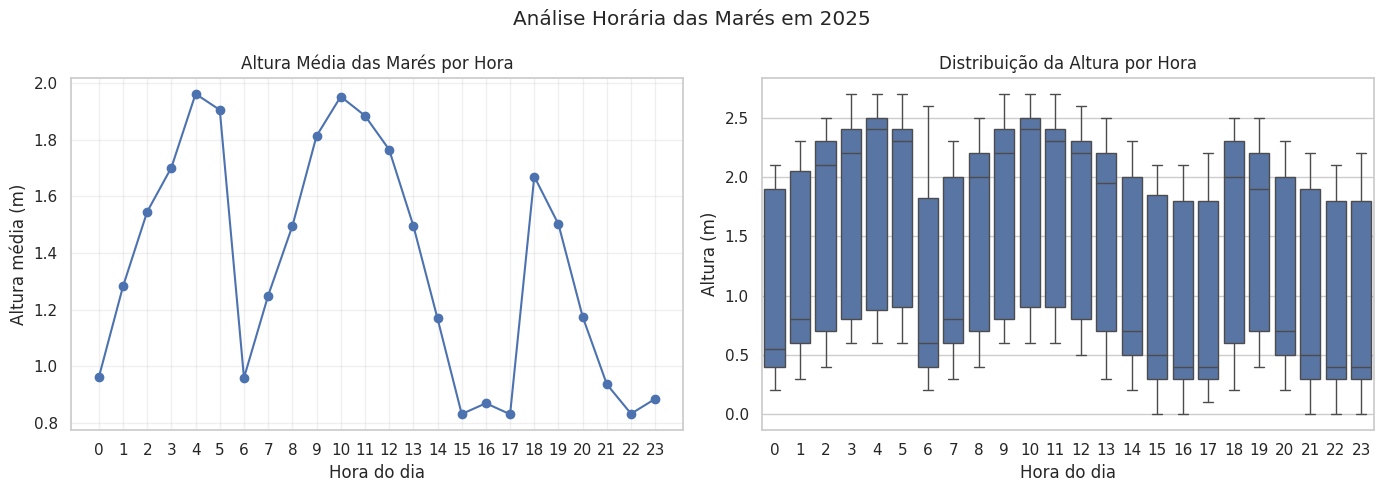

In [858]:

# Criar a variável hora a partir da data e hora do evento
dados_horarios = df_mares_2025_limpo.copy()
dados_horarios["hora"] = dados_horarios["data_hora"].dt.hour

fig, eixos = plt.subplots(1, 2, figsize=(14, 5))

# Gráfico 1: altura média por hora
media_hora = dados_horarios.groupby("hora")["altura_m"].mean()

eixos[0].plot(media_hora.index, media_hora.values, marker="o")
eixos[0].set_title("Altura Média das Marés por Hora")
eixos[0].set_xlabel("Hora do dia")
eixos[0].set_ylabel("Altura média (m)")
eixos[0].set_xticks(range(0, 24))
eixos[0].grid(alpha=0.3)

# Gráfico 2: distribuição da altura por hora
sns.boxplot(
    data=dados_horarios,
    x="hora",
    y="altura_m",
    ax=eixos[1]
)
eixos[1].set_title("Distribuição da Altura por Hora")
eixos[1].set_xlabel("Hora do dia")
eixos[1].set_ylabel("Altura (m)")

fig.suptitle("Análise Horária das Marés em 2025")
plt.tight_layout()
plt.show()


### 2. Histogramas — altura e coeficiente das marés

A altura apresenta dois grupos de concentração, compatíveis com marés altas e baixas. Já os coeficientes se concentram principalmente em valores intermediários, com menor frequência nos extremos.

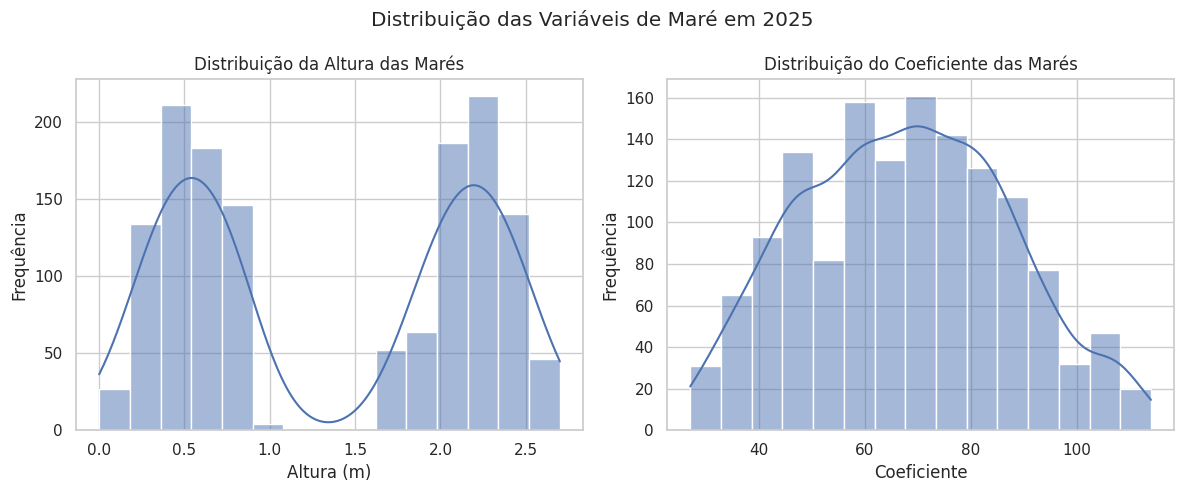

In [859]:
fig, eixos = plt.subplots(1, 2, figsize=(12, 5))

# Histograma da altura com curva KDE
sns.histplot(
    data=df_mares_2025_limpo,
    x="altura_m",
    bins=15,
    kde=True,
    ax=eixos[0]
)
eixos[0].set_title("Distribuição da Altura das Marés")
eixos[0].set_xlabel("Altura (m)")
eixos[0].set_ylabel("Frequência")

# Histograma do coeficiente com curva KDE
sns.histplot(
    data=df_mares_2025_limpo,
    x="coeficiente_num",
    bins=15,
    kde=True,
    ax=eixos[1]
)
eixos[1].set_title("Distribuição do Coeficiente das Marés")
eixos[1].set_xlabel("Coeficiente")
eixos[1].set_ylabel("Frequência")

fig.suptitle("Distribuição das Variáveis de Maré em 2025")
plt.tight_layout()
plt.show()



### 3. Dispersão — altura × coeficiente

O gráfico apresenta dois padrões distintos, provavelmente associados às marés altas e baixas. Isso indica que a relação entre altura e coeficiente deve ser interpretada considerando os diferentes tipos de evento.



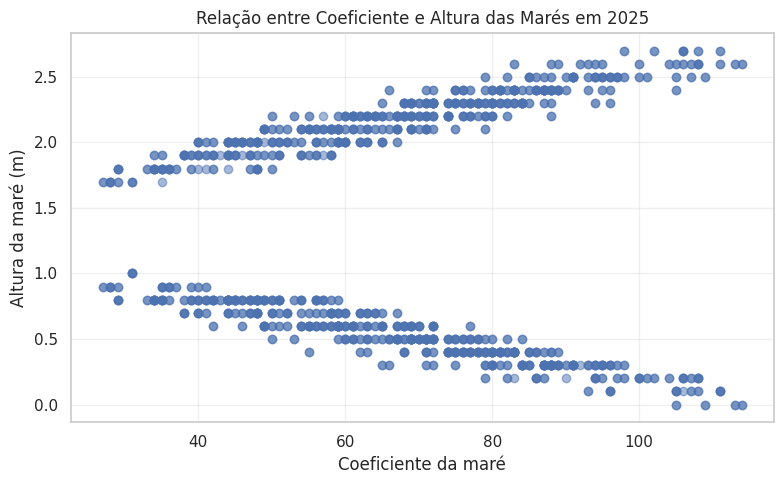

In [860]:

dados = df_mares_2025_limpo.dropna(
    subset=["altura_m", "coeficiente_num"]
)

plt.figure(figsize=(8, 5))

plt.scatter(
    dados["coeficiente_num"],
    dados["altura_m"],
    alpha=0.5
)

plt.title("Relação entre Coeficiente e Altura das Marés em 2025")
plt.xlabel("Coeficiente da maré")
plt.ylabel("Altura da maré (m)")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()



----

# Marés de Outubro de 2026

### Análise horária da altura das marés

- A altura média apresenta variações ao longo do dia, com valores mais elevados entre as 3h e 5h e entre as 10h e 12h.
- O menor valor médio ocorre por volta das 16h, quando a altura fica próxima de 0,3 m.
- O boxplot mostra uma grande variação de altura em determinados horários, indicando que a maré não apresenta sempre a mesma altura em uma hora específica.

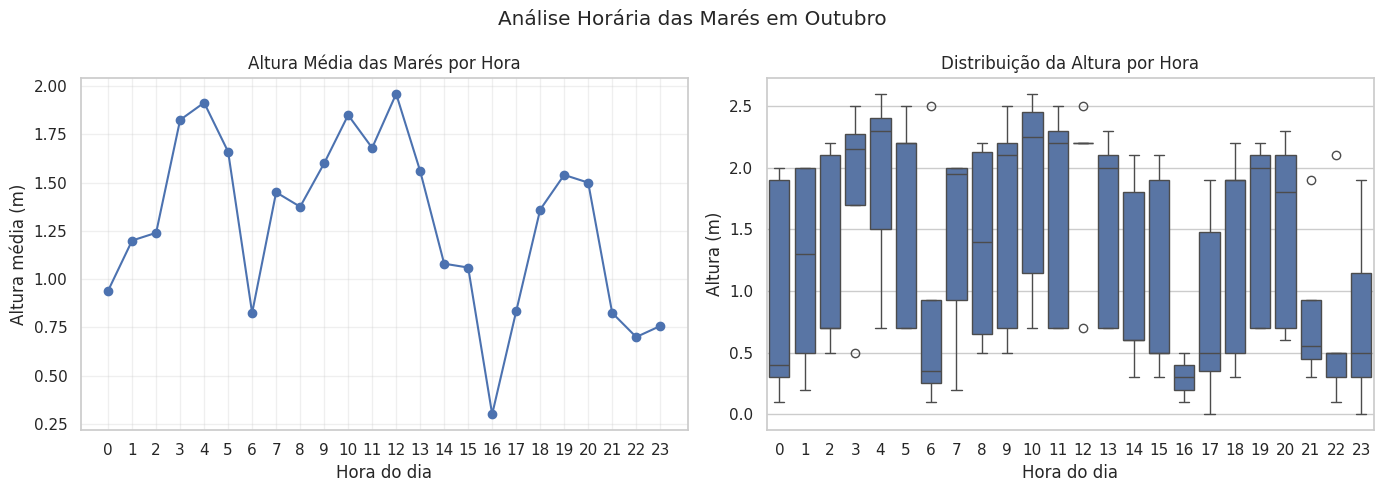

In [861]:

# Criar a variável hora a partir da data e hora
dados_horarios = df_mares_prev_limpo.copy()
dados_horarios["hora"] = dados_horarios["data_hora"].dt.hour

fig, eixos = plt.subplots(1, 2, figsize=(14, 5))

# Gráfico 1: altura média por hora
media_hora = dados_horarios.groupby("hora")["altura_m"].mean()

eixos[0].plot(media_hora.index, media_hora.values, marker="o")
eixos[0].set_title("Altura Média das Marés por Hora")
eixos[0].set_xlabel("Hora do dia")
eixos[0].set_ylabel("Altura média (m)")
eixos[0].set_xticks(range(0, 24))
eixos[0].grid(alpha=0.3)

# Gráfico 2: distribuição da altura por hora
sns.boxplot(
    data=dados_horarios,
    x="hora",
    y="altura_m",
    ax=eixos[1]
)
eixos[1].set_title("Distribuição da Altura por Hora")
eixos[1].set_xlabel("Hora do dia")
eixos[1].set_ylabel("Altura (m)")

fig.suptitle("Análise Horária das Marés em Outubro")
plt.tight_layout()
plt.show()


### Variação do coeficiente das marés

- No início do mês, o coeficiente está próximo de 98 e diminui gradualmente até atingir valores em torno de 46 entre os dias 8 e 10.
- Em seguida, aumenta até aproximadamente 79 por volta dos dias 15 e 16, voltando a diminuir até atingir cerca de 42 entre os dias 23 e 25.
- No final do mês, ocorre um aumento acentuado, chegando a aproximadamente 111 nos dias 30 e 31.

Se compararmos semana a semana, é possível observar uma variação de uma para uma com coeficientes altos e baixos.

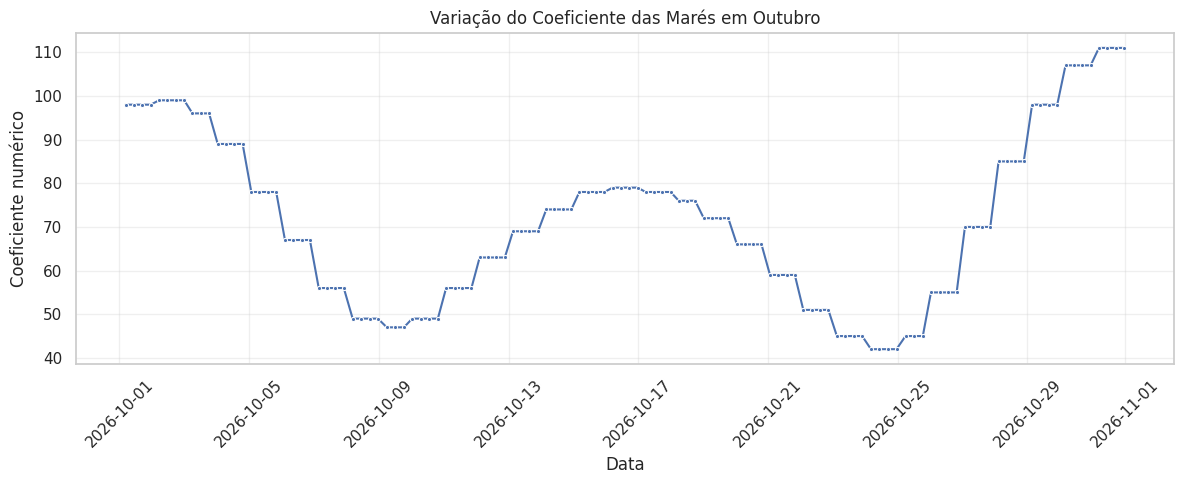

In [862]:

df_coef = df_mares_prev.copy()

df_coef["data_hora"] = pd.to_datetime(df_coef["data_hora"])

df_coef["coeficiente_num"] = pd.to_numeric(
    df_coef["coeficiente"].astype(str).str.extract(r"(\d+(?:[.,]\d+)?)")[0]
    .str.replace(",", ".", regex=False),
    errors="coerce"
)

df_coef = df_coef.dropna(subset=["data_hora", "coeficiente_num"]).sort_values("data_hora")

plt.figure(figsize=(12, 5))

sns.lineplot(
    data=df_coef,
    x="data_hora",
    y="coeficiente_num",
    marker="o",
    markersize=3
)

plt.title("Variação do Coeficiente das Marés em Outubro")
plt.xlabel("Data")
plt.ylabel("Coeficiente numérico")
plt.xticks(rotation=45)
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()


#### Conclusão geral
Os gráficos mostram que as marés apresentam variações tanto ao longo do dia quanto ao longo do mês. A altura varia entre períodos de maré mais baixa e mais alta, enquanto o coeficiente apresenta ciclos de diminuição e aumento.


----



# Análise ondas e ventos de Outubro de 2026

### Altura das Ondas e Velocidade

Analisando a distribuição agregada ao longo das 24 horas, conseguimos responder diretamente aos objetivos de comportamento diário do mar e do vento:

* **Padrão Horário das Ondas (Esquerda)**:
  * A faixa de altura mantém-se muito estável ao longo de todo o dia, oscilando predominantemente entre **1.2m e 1.3m** (com a mediana cravada nos 1.2m na maioria das horas).
  * Os quartis e os limites mostram que **não existe um padrão diário marcante** na altura; a variação do tamanho das ondas é ditada por fatores de longo prazo (dias), e não pelas horas do dia.

* **Velocidade e Horas Mais Calmas do Vento (Direita)**:
  * A velocidade média do vento oscila numa faixa entre **20 km/h e 23 km/h** ao longo do dia.
  * Identifica-se uma subtil janela de menor intensidade (as horas mais calmas) no período da **tarde/fim de tarde (por volta das 14h às 16h)**, onde a média baixa para cerca de 20 km/h.

* **O Fator Crítico: Direção do Vento (Terral vs. Maral)**:
  * Além da velocidade, a **direção predominante** ao longo do dia joga um papel decisivo na qualidade do surf.
  * Ventos que sopram da terra para o mar (*terral*) limpam a crista da onda e criam paredes perfeitas, enquanto ventos do mar para a terra (*maral*) deixam o mar batido e mexido. Cruzar a variação horária da direção com estes períodos de menor intensidade será o grande diferencial para o ranqueamento do modelo.

* **Conclusão para o Projeto**:
  * Como a altura da onda é estável ao longo das horas, o sucesso do ranqueamento dependerá principalmente da **sinergia entre a velocidade e a direção do vento** em cada faixa horária do dia.

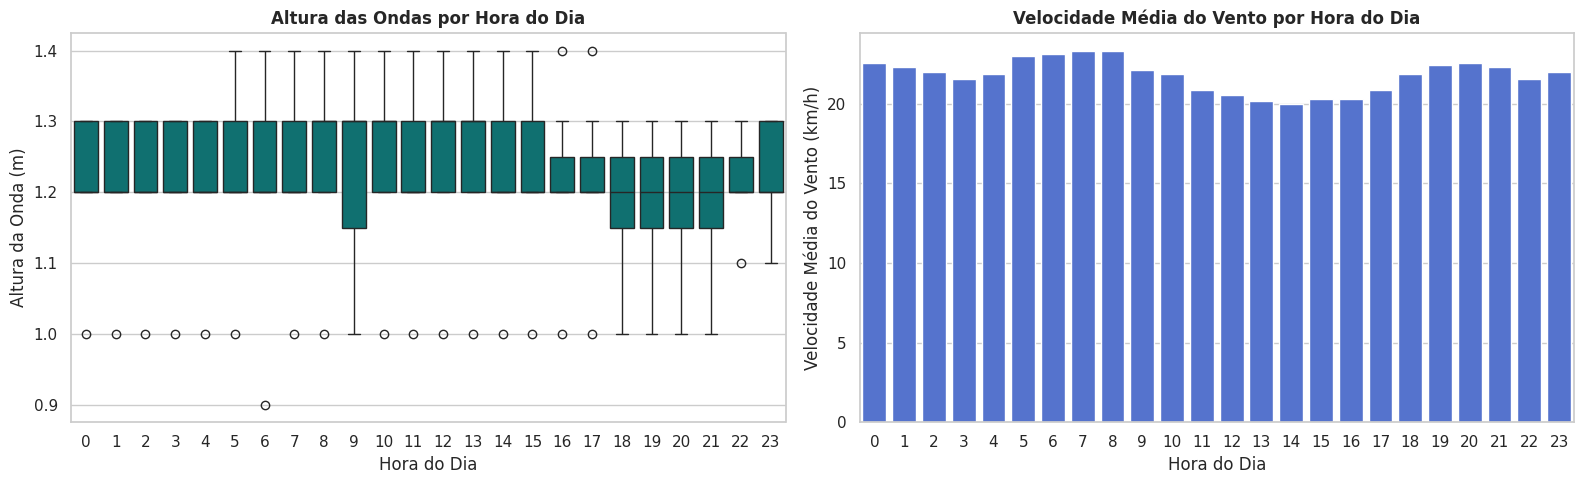

In [863]:
sns.set_theme(style="whitegrid")

fig, eixos = plt.subplots(1, 2, figsize=(16, 5))

df_ondas_limpo["hora"] = df_ondas_limpo["data_hora"].dt.hour
df_vento_limpo["hora"] = df_vento_limpo["data_hora"].dt.hour

# 1. Gráfico de Ondas por Hora do Dia (Boxplot)
sns.boxplot(
    data=df_ondas_limpo,
    x="hora",
    y="altura_onda",
    color="teal",
    ax=eixos[0]
)
eixos[0].set_title("Altura das Ondas por Hora do Dia", fontsize=12, fontweight='bold')
eixos[0].set_xlabel("Hora do Dia")
eixos[0].set_ylabel("Altura da Onda (m)")

# 2. Gráfico de Vento por Hora do Dia (Média por Barplot)
vento_por_hora = df_vento_limpo.groupby("hora")["velocidade_vento"].mean().reset_index()

sns.barplot(
    data=vento_por_hora,
    x="hora",
    y="velocidade_vento",
    color="royalblue",
    ax=eixos[1]
)
eixos[1].set_title("Velocidade Média do Vento por Hora do Dia", fontsize=12, fontweight='bold')
eixos[1].set_xlabel("Hora do Dia")
eixos[1].set_ylabel("Velocidade Média do Vento (km/h)")

plt.tight_layout()
plt.show()

### Altura das Ondas vs. Velocidade do Vento

Analisando a variação hora a hora, destacam-se os seguintes padrões:

- **Comportamento das Ondas**:
  - A altura das ondas mantém-se relativamente estável e moderada, oscilando predominantemente entre **1.0m e 1.4m**.
  - Identifica-se um claro aumento de energia (*swell*) a partir de 13 de outubro, atingindo o pico máximo de **1.4m** nos dias 14 e 15 de outubro, antes de iniciar uma descida gradual rumo ao dia 18.

- **Comportamento do Vento**:
  - A velocidade do vento apresenta alta volatilidade ao longo do período, variando numa faixa ampla entre **15 km/h e 30 km/h**.
  - Regista-se uma rajada mais forte no início do período (próximo de 30 km/h em 11 de outubro) e vales de menor intensidade (cerca de 15 km/h) por volta do dia 15.

- **Interação e Impacto para o Surf (Sinergia)**:
  - O gráfico cruzado permite observar que os picos de altura de onda (**1.4m nos dias 14 e 15**) coincidem temporalmente com momentos em que a velocidade do vento regista uma descompressão/queda (aproximando-se dos 16–18 km/h após vales acentuados). 
  - Esta janela (14–15 de outubro) representa o cenário ideal para o surf na costa de João Pessoa: **bom tamanho de onda combinado com menor turbulência eólica**, o que favorece a formação de paredes limpas em vez de um mar batido (*maral*).

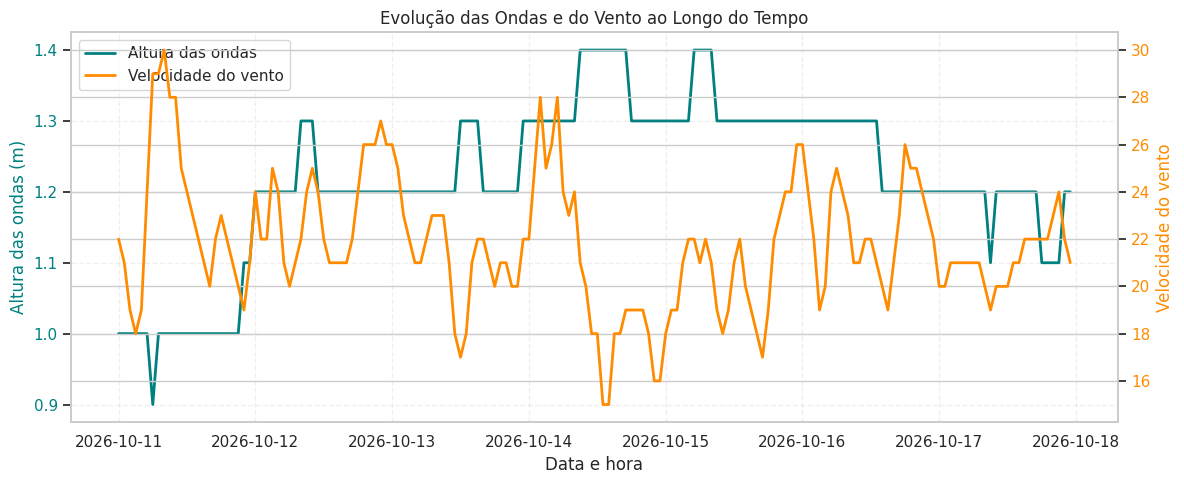

In [864]:
dados_relacao = pd.merge(
    df_ondas_limpo[["data_hora", "altura_onda"]],
    df_vento_limpo[["data_hora", "velocidade_vento"]],
    on="data_hora",
    how="inner"
).dropna()

fig, eixo1 = plt.subplots(figsize=(12, 5))

linha1 = eixo1.plot(
    dados_relacao["data_hora"],
    dados_relacao["altura_onda"],
    color="teal",
    linewidth=2,
    label="Altura das ondas"
)
eixo1.set_xlabel("Data e hora")
eixo1.set_ylabel("Altura das ondas (m)", color="teal")
eixo1.tick_params(axis="y", labelcolor="teal")
eixo1.grid(True, linestyle="--", alpha=0.3)

eixo2 = eixo1.twinx()
linha2 = eixo2.plot(
    dados_relacao["data_hora"],
    dados_relacao["velocidade_vento"],
    color="darkorange",
    linewidth=2,
    label="Velocidade do vento"
)
eixo2.set_ylabel("Velocidade do vento", color="darkorange")
eixo2.tick_params(axis="y", labelcolor="darkorange")

linhas = linha1 + linha2
eixo1.legend(linhas, [linha.get_label() for linha in linhas],
             loc="upper left")

plt.title("Evolução das Ondas e do Vento ao Longo do Tempo")
plt.tight_layout()
plt.show()

## 4. Juntar as tabelas

Esta é a parte difícil, e ela tem mais de uma resposta certa.

As granularidades não batem: onda e vento são leituras horárias; maré são ~4
eventos por dia (os instantes de máxima e mínima). Para ter uma linha por hora
com as três informações você precisa decidir:

- Como levar a maré para a grade horária? Interpolar entre eventos? Repetir o
  último valor? Guardar apenas se a maré está subindo ou descendo? O que cada
  escolha assume sobre a curva real da maré — e onde essa suposição erra?
- Qual o tipo de junção? A previsão de onda e a de vento cobrem exatamente as
  mesmas horas? Se não, você mantém as horas incompletas ou corta?
- Que variáveis derivadas de tempo ajudam a responder a pergunta do projeto
  (dia da semana, período do dia, ...)?

Justifique as escolhas em markdown. Elas são a base das duas próximas etapas.

In [865]:
start_date = max(df_ondas_limpo["data_hora"].min(), df_vento_limpo["data_hora"].min())
end_date = min(df_ondas_limpo["data_hora"].max(), df_vento_limpo["data_hora"].max())

grade_horaria = pd.DataFrame({
    "data_hora": pd.date_range(start=start_date, end=end_date, freq="h")
})

df_mares_indexed = df_mares_prev_limpo.drop_duplicates(subset=["data_hora"]).set_index("data_hora").sort_index()

df_unificado = pd.concat([
    df_mares_indexed, 
    pd.DataFrame(index=grade_horaria["data_hora"])
]).sort_index()

df_unificado["altura_m"] = df_unificado["altura_m"].interpolate(method="time")
df_unificado["coeficiente_num"] = df_unificado["coeficiente_num"].ffill().bfill()
df_unificado["coeficiente_desc"] = df_unificado["coeficiente_desc"].ffill().bfill()

df_unificado = df_unificado.loc[grade_horaria["data_hora"]].reset_index()

dataset_final = df_unificado.merge(df_ondas_limpo, on="data_hora", how="inner")
dataset_final = dataset_final.merge(df_vento_limpo, on="data_hora", how="inner")

dataset_final["ano"] = dataset_final["data_hora"].dt.year   
dataset_final["mes"] = dataset_final["data_hora"].dt.month
dataset_final["dia"] = dataset_final["data_hora"].dt.day
dataset_final["hora"] = dataset_final["data_hora"].dt.hour
dataset_final["dia_da_semana"] = dataset_final["data_hora"].dt.day_name()
dataset_final["coeficiente_num"] = dataset_final["coeficiente_num"].astype(int)
dataset_final["altura_m"] = dataset_final["altura_m"].round(1)

In [866]:
display(dataset_final.sample(5))

,data_hora,altura_m,coeficiente_num,coeficiente_desc,direcao_onda,altura_onda,hora_x,direcao_vento,velocidade_vento,hora_y,ano,mes,dia,hora,dia_da_semana
15,2026-10-11 15:00:00,0.7,56,médio,ESE,1.0,15,ESE,21,15,2026,10,11,15,Sunday
64,2026-10-13 16:00:00,0.5,69,médio,E,1.2,16,ESE,22,16,2026,10,13,16,Tuesday
99,2026-10-15 03:00:00,1.8,74,alto,E,1.3,3,E,21,3,2026,10,15,3,Thursday
18,2026-10-11 18:00:00,0.7,56,médio,E,1.0,18,SE,23,18,2026,10,11,18,Sunday
9,2026-10-11 09:00:00,1.8,56,médio,ESE,1.0,9,ESE,28,9,2026,10,11,9,Sunday


#### **Delimitação da Janela Temporal de Análise**
  * A união concentrou-se estritamente no período de interseção exata entre os registos de ondas e vento (de 11 a 17 de outubro de 2026). O histórico de marés de 2025 permaneceu separado, sendo ideal para análises globais de sazonalidade anual.

#### **Construção de uma Grelha Horária Contínua**
  * Estabeleceu-se um índice temporal contínuo de hora em hora (`freq="h"`), servindo como a espinha dorsal para alinhar todas as variáveis ambientais de forma síncrona.

#### **Interpolação Temporal da Altura da Maré**
  * Como as previsões de maré originais ocorrem apenas em instantes pontuais (picos de maré alta e baixa, cerca de quatro vezes por dia), combinou-se esses pontos com a grelha horária e aplicou-se uma **interpolação linear temporal** (`interpolate(method="time")`). Esta técnica simula de forma realista a transição contínua da subida e descida do nível da água entre os picos.

#### **Propagação dos Coeficientes de Maré (`ffill` e `bfill`)**
  * Para os coeficientes de maré (que traduzem a amplitude e características gerais do período), utilizou-se o preenchimento sequencial para a frente e para trás (`ffill`/`bfill`). Isto assegura que cada hora do ciclo reflita o coeficiente correto sem gerar valores omissos.

#### **Cruzamento Final (`Inner Join`)**
  * Por fim, realizou-se o cruzamento exato com as tabelas horárias de ondas e vento, resultando num dataset unificado limpo, consistente e totalmente livre de valores nulos (`NaN`).

  

----

## 5. Visualizações voltadas à pergunta

Agora com a tabela junta: quando as condições coincidem?

- As horas de onda maior são as mesmas de vento mais fraco, ou elas se
  desencontram?
- Existe relação visível entre altura da maré e altura da onda?
- Quais dias e horas da janela se destacam?

Prefira poucos gráficos legíveis a muitos gráficos.

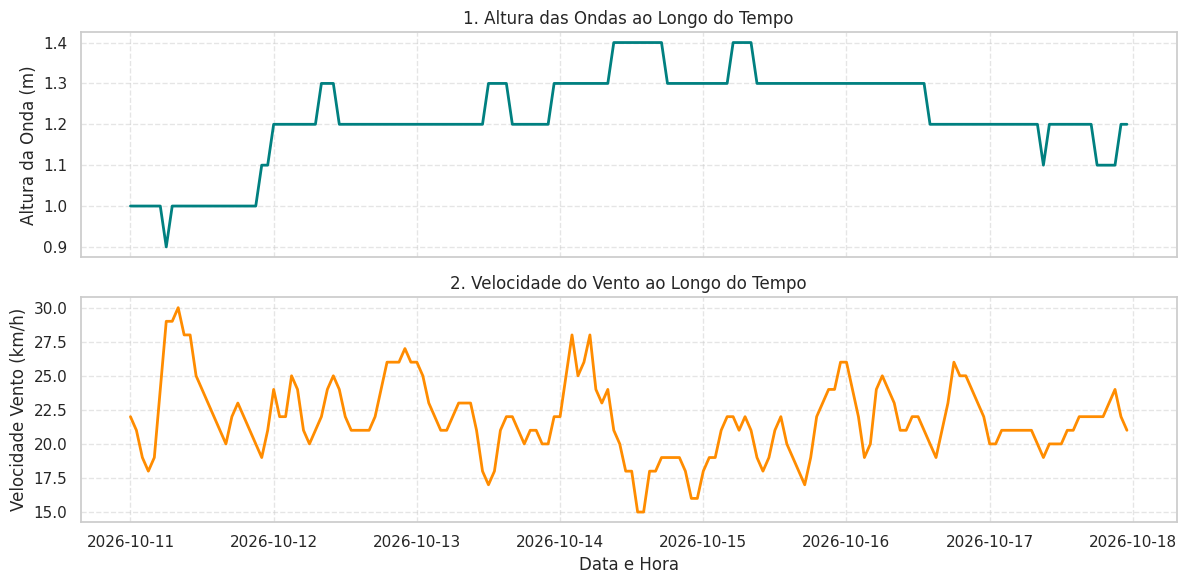

In [867]:
fig, axes = plt.subplots(2, 1, figsize=(12, 6), sharex=True)

axes[0].plot(dataset_final['data_hora'], dataset_final['altura_onda'], color='teal', linewidth=2)
axes[0].set_ylabel('Altura da Onda (m)')
axes[0].set_title('1. Altura das Ondas ao Longo do Tempo')
axes[0].grid(True, linestyle='--', alpha=0.5)

axes[1].plot(dataset_final['data_hora'], dataset_final['velocidade_vento'], color='darkorange', linewidth=2)
axes[1].set_ylabel('Velocidade Vento (km/h)')
axes[1].set_xlabel('Data e Hora')
axes[1].set_title('2. Velocidade do Vento ao Longo do Tempo')
axes[1].grid(True, linestyle='--', alpha=0.5)

plt.tight_layout()
plt.show()

### Análise do Gráfico 1 (Série Temporal Empilhada: Ondas vs. Vento)

* Os gráficos de evolução temporal mostram claramente que os maiores picos de ondas e os ventos mais fortes **se desencontram temporalmente**. Enquanto a velocidade do vento atinge os seus pontos máximos no início da janela (dia 11/10 chegando a 30 km/h) e em 14/10, os maiores picos de altura de onda (1.4 m) registam-se logo em seguida, entre os dias **14 e 15 de outubro**.
---

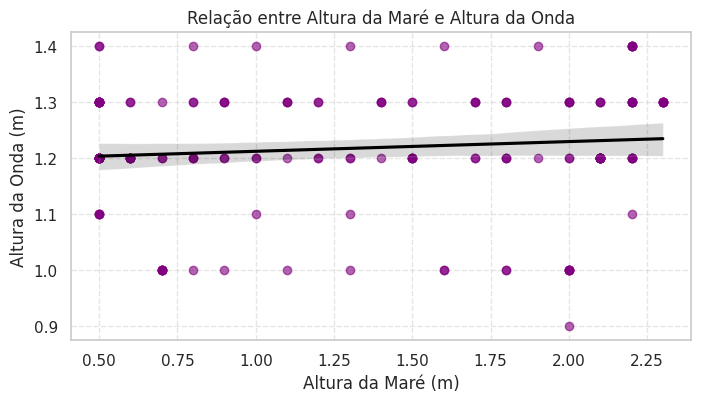

In [868]:
plt.figure(figsize=(8, 4))
sns.regplot(
    x=dataset_final["altura_m"], 
    y=dataset_final["altura_onda"], 
    color='purple', 
    scatter_kws={'alpha': 0.6}, 
    line_kws={'color': 'black'}
)
plt.title('Relação entre Altura da Maré e Altura da Onda')
plt.xlabel('Altura da Maré (m)')
plt.ylabel('Altura da Onda (m)')
plt.grid(True, linestyle='--', alpha=0.5)
plt.show()

### Análise 2: Relação entre Maré e Ondas

* O gráfico de dispersão com linha de tendência indica que **não há uma relação visível ou correlação significativa** entre a altura da maré e a altura das ondas. A linha de regressão mantém-se praticamente horizontal ao longo de toda a variação da maré (de 0.5 m a 2.3 m), demonstrando que a altura das ondas permanece estável (majoritariamente em torno de 1.2 m a 1.3 m) independentemente de o nível da maré estar alto ou baixo.
---

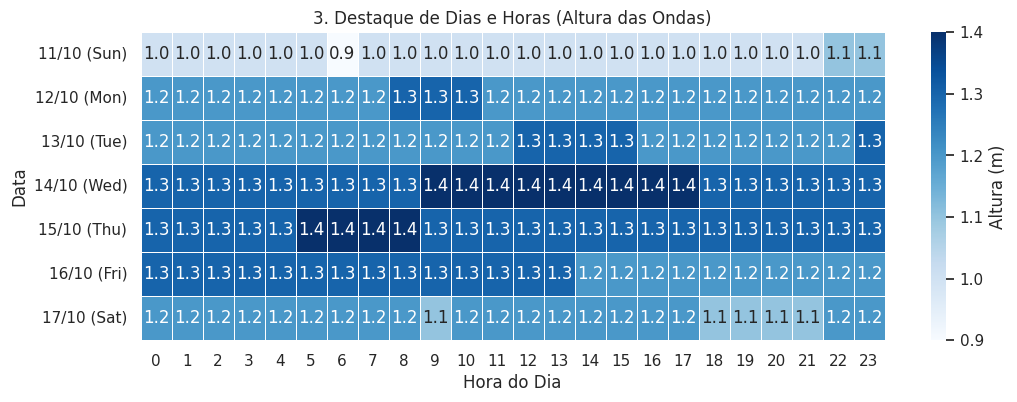

In [869]:
pivot_ondas = dataset_final.pivot_table(
    index=dataset_final['data_hora'].dt.strftime('%d/%m (%a)'), 
    columns=dataset_final['data_hora'].dt.hour, 
    values='altura_onda'
)

plt.figure(figsize=(12, 4))
sns.heatmap(
    pivot_ondas, 
    cmap="Blues", 
    annot=True, 
    fmt=".1f", 
    cbar_kws={'label': 'Altura (m)'},
    linewidths=0.5
)
plt.title('3. Destaque de Dias e Horas (Altura das Ondas)')
plt.xlabel('Hora do Dia')
plt.ylabel('Data')
plt.show()

### Análise 3: Destaque de Dias e Horas

* O mapa de calor evidencia que os momentos de maior agitação marítima concentram-se de forma consistente nos dias **14 de outubro (quarta-feira)** e **15 de outubro (quinta-feira)**. No que diz respeito aos horários, os maiores valores de altura de onda (atingindo o máximo de 1.4 metros) destacam-se nitidamente nas **primeiras horas da manhã, especificamente entre as 05:00h e as 09:00h**.

___

## 6. Salvar o dataset processado

Grave o resultado em `../data/processed/dataset.csv`. A Etapa 3 lê esse
arquivo — se as colunas mudarem depois, o notebook de ML muda também.

In [ ]:
Path("../data/processed").mkdir(parents=True, exist_ok=True)
dataset_final.to_csv("../data/processed/dataset.csv", index=False)

## 7. Conclusões

Em texto, sem código:

1. O que os dados mostram sobre as condições da janela coletada?

   *Os dados mostram um comportamento bem consistente para o período analisado. Nas marés, identifica-se um ciclo diário regular, com as alturas máximas concentradas nas primeiras horas da manhã e os valores mínimos no período da tarde. No caso das ondas e ventos, a altura das ondas fica em torno de 1,2 metro, vindo predominantemente de Leste e Leste-Sudeste, acompanhada por ventos moderados (entre 18 e 30 km/h) que sopram nas mesmas direções, o que aponta para uma forte influência do vento na dinâmica costeira da região.***

2. Que decisão de limpeza ou de junção você tomou que mais influencia oresultado, e por quê?

   *A decisão de limpeza que mais influenciou o resultado foi o tratamento inicial dos dados brutos, que incluiu a remoção de unidades de medida, a conversão de vírgulas para pontos decimais e a padronização dos tipos numéricos e de data. Sem essa normalização, qualquer cálculo analítico seria inviável. Na parte de estruturação, alinhar rigorosamente o eixo temporal em formato horário foi fundamental para garantir que a junção das tabelas de maré, onda e vento acontecesse de forma sincronizada, sem distorções ou perda de informações.*

3. O que esses dados **não** permitem afirmar?

   *Estes dados não permitem afirmar como o clima ou o mar vão se comportar fora dessa janela de tempo analisada, pois servem apenas para o retrato específico do período coletado. Além disso, por se tratarem de informações gerais da região, eles não mostram detalhes específicos de cada praia ou trecho de costa, sendo necessário buscar dados mais locais para análises detalhadas daquela área específica.*